# T11 — EDA Oxford-IIIT Pet
**Thực hiện:** Edward2106 · **Review:** Bambizled · Issue #1

Khám phá 37 giống chó/mèo để xác định yêu cầu preprocessing ViT-B/16. Chỉ thống kê mô tả, không train, không chọn tham số bằng test. Phân tích riêng official trainval/test và tổng hợp; không tạo split mới.

## Chạy lại
Cài `pip install pillow pandas matplotlib nbformat nbclient ipykernel`. Đặt biến môi trường `OXFORD_PET_ROOT` tới thư mục chứa `images/` và `annotations/`, hoặc đặt dataset tại `data/oxford-iiit-pet`. Mở notebook từ gốc repo hoặc `notebooks/`, Restart & Run All. CPU đủ, không checkpoint/GPU/download tự động. Không ghi vào dataset.

Kế thừa vòng đọc annotation, `Image.load()` và kiểm tra mode từ project cá nhân `vit_pets/audit.py`; tái sử dụng nguyên bản audit.json/class_counts.csv để đối chiếu. Không import pipeline train hoặc sao chép toàn project. Hash nguồn trong `results/eda/reference/provenance.json`.

In [1]:
from pathlib import Path
import os, json, hashlib, warnings, platform
import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import PIL
from PIL import Image, ImageOps
from IPython.display import display, Markdown
SEED = 42
ROOT = Path.cwd().resolve()
if ROOT.name == 'notebooks': ROOT = ROOT.parent
assert (ROOT/'notebooks').is_dir(), 'Chạy từ gốc repository hoặc notebooks/'
DATA = Path(os.environ.get('OXFORD_PET_ROOT', str(ROOT/'data/oxford-iiit-pet'))).expanduser()
if not (DATA/'images').is_dir() or not (DATA/'annotations').is_dir():
    raise FileNotFoundError('Thiếu dataset. Đặt OXFORD_PET_ROOT tới thư mục chứa images/ và annotations/.')
FIG = ROOT/'figures/eda'; FIG.mkdir(parents=True, exist_ok=True)
RESULT = ROOT/'results/eda'; RESULT.mkdir(parents=True, exist_ok=True)
def save(name):
    plt.tight_layout(); plt.savefig(FIG/name, dpi=120, bbox_inches='tight'); plt.show(); plt.close()
print({'python':platform.python_version(),'pillow':PIL.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__})

{'python': '3.11.9', 'pillow': '12.2.0', 'pandas': '3.0.3', 'matplotlib': '3.10.9'}


## 1. Annotation chính thức và phạm vi
Đọc đủ bốn cột ID, class ID, species ID, breed ID. Species **1=Cat, 2=Dog** theo annotation; tuyệt đối không suy loài từ chữ hoa/thường. Tên hiển thị giống lấy phần tên trong ID **sau khi nhóm theo class ID chính thức**, kiểm tra mỗi class chỉ có một tên/loài. Kiểm tra list.txt so với union trainval/test. Chỉ các ID trong official split là mẫu phân loại; kiểm kê ảnh ngoài annotation riêng. Không đếm trimap làm ảnh đầu vào.

In [2]:
def annotations(name):
    rows=[]
    for line in (DATA/'annotations'/f'{name}.txt').read_text().splitlines():
        if line.strip() and not line.startswith('#'):
            ident, cls, species, breed = line.split()
            rows.append((ident,int(cls),int(species),int(breed)))
    frame=pd.DataFrame(rows,columns=['id','class_id','species_id','breed_id'])
    assert not frame.id.duplicated().any(), f'ID trùng trong {name}'
    assert frame.species_id.isin([1,2]).all()
    return frame
parts=[]
for split in ['trainval','test']:
    part=annotations(split); part['split']=split; parts.append(part)
a=pd.concat(parts,ignore_index=True)
assert not a.id.duplicated().any(), 'Overlap official split'
listing=annotations('list')
assert set(map(tuple,a[listing.columns].values))==set(map(tuple,listing.values))
a['species']=a.species_id.map({1:'Cat',2:'Dog'})
a['class_name']=a.id.str.rsplit('_',n=1).str[0]
assert a.class_id.nunique()==37
assert (a.groupby('class_id')[['species_id','class_name','breed_id']].nunique()==1).all().all()
display(a.groupby('split').size().rename('images').to_frame())
display(a.groupby('class_id')[['class_name','species']].first())
expected=set(a.id+'.jpg')
entries=list((DATA/'images').iterdir())
metadata=sorted(p.name for p in entries if p.name.startswith('._'))
extra=sorted(p.name for p in entries if p.is_file() and p.suffix.lower() in ['.jpg','.jpeg','.png'] and not p.name.startswith('._') and p.name not in expected)
other=sorted(p.name for p in entries if p.is_file() and not p.name.startswith('._') and p.suffix.lower() not in ['.jpg','.jpeg','.png'])
inventory={'annotated_images':len(a),'metadata_files':metadata,'unannotated_images':extra,'other_files':other,'trimaps_excluded':True}
print({k:len(v) if isinstance(v,list) else v for k,v in inventory.items()})
(RESULT/'inventory.json').write_text(json.dumps(inventory,indent=2))

,images
split,
test,3669
trainval,3680


,class_name,species
class_id,,
1,Abyssinian,Cat
2,american_bulldog,Dog
3,american_pit_bull_terrier,Dog
4,basset_hound,Dog
5,beagle,Dog
6,Bengal,Cat
7,Birman,Cat
8,Bombay,Cat
9,boxer,Dog


{'annotated_images': 7349, 'metadata_files': 0, 'unannotated_images': 41, 'other_files': 3, 'trimaps_excluded': True}


1297

## 2. Phân bố 37 lớp và loài
Bảng có từng split để phân biệt phân bố gốc và tổng hợp. Tỉ lệ loài không tương đương mức cân bằng giữa các giống.

,,split,test,trainval,total
class_id,class_name,species,,,
1,Abyssinian,Cat,98,100,198
2,american_bulldog,Dog,100,100,200
3,american_pit_bull_terrier,Dog,100,100,200
4,basset_hound,Dog,100,100,200
5,beagle,Dog,100,100,200
6,Bengal,Cat,100,100,200
7,Birman,Cat,100,100,200
8,Bombay,Cat,88,96,184
9,boxer,Dog,99,100,199


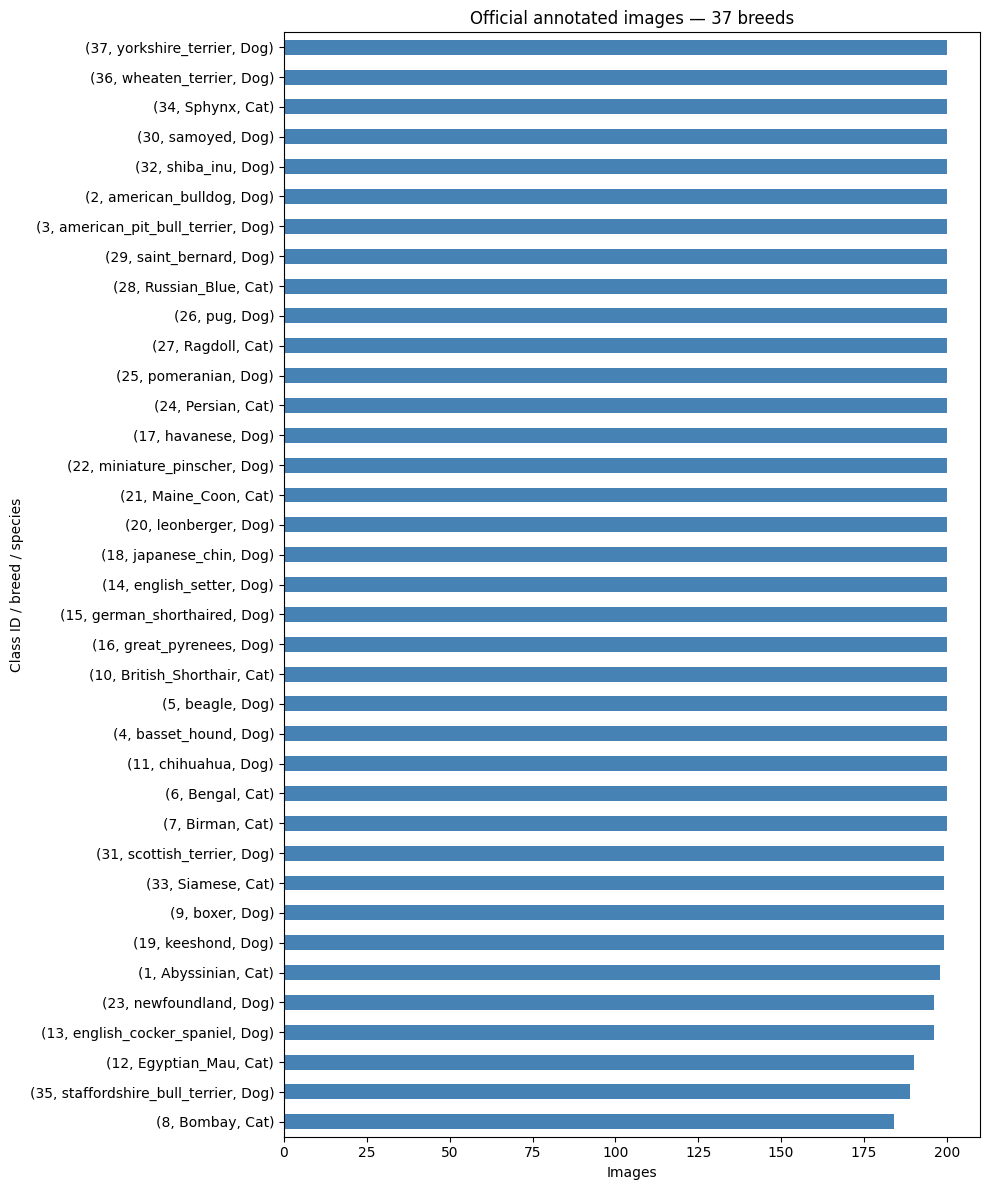

,images,percent
species,,
Cat,2371,32.262893
Dog,4978,67.737107


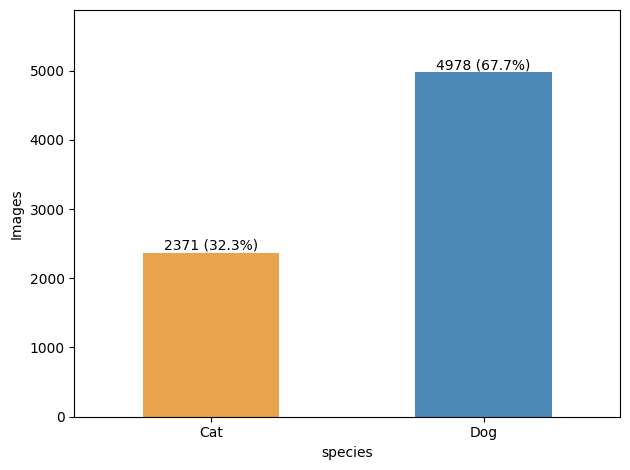

In [3]:
counts=pd.crosstab([a.class_id,a.class_name,a.species],a['split'])
counts['total']=counts.sum(axis=1); display(counts)
counts.to_csv(RESULT/'class_counts.csv')
counts['total'].sort_values().plot.barh(figsize=(10,12),color='steelblue')
plt.xlabel('Images'); plt.ylabel('Class ID / breed / species'); plt.title('Official annotated images — 37 breeds'); save('class_distribution.png')
species=a.groupby('species').size(); display(pd.DataFrame({'images':species,'percent':species/len(a)*100}))
species.plot.bar(rot=0,color=['#e9a34c','#4b88b5']); plt.ylabel('Images')
for i,v in enumerate(species): plt.text(i,v,f'{v} ({v/len(a):.1%})',ha='center',va='bottom')
plt.ylim(0,species.max()*1.18); save('species_distribution.png')
assert counts.total.sum()==species.sum()==len(a)

## 3. Giải mã toàn bộ ảnh và kiểm tra mode
Giữ mode và kích thước **gốc trước EXIF transpose**, gọi load() để phát hiện lỗi giải mã thay vì chỉ đọc header. Ảnh thiếu, lỗi decode và kích thước không hợp lệ được tách biệt. Non-RGB đọc được không phải ảnh hỏng. Lưu warnings và ID cụ thể; không bật LOAD_TRUNCATED_IMAGES.

,id,class_id,species_id,breed_id,split,species,class_name,status,mode,width,height,warning,error
2395,Egyptian_Mau_14,12,1,6,trainval,Cat,Egyptian_Mau,ok,RGBA,582,800,,
2427,Egyptian_Mau_186,12,1,6,trainval,Cat,Egyptian_Mau,ok,RGBA,183,275,,
3735,Abyssinian_5,1,1,1,test,Cat,Abyssinian,ok,RGBA,200,150,,


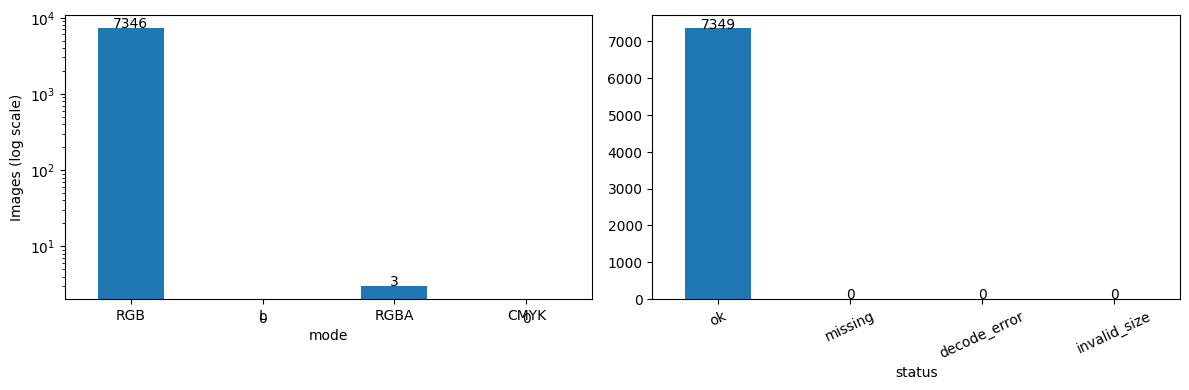

In [4]:
records=[]
for row in a.itertuples(index=False):
    p=DATA/'images'/f'{row.id}.jpg'
    rec={'id':row.id,'status':'ok','mode':None,'width':None,'height':None,'warning':'','error':''}
    if not p.is_file(): rec.update(status='missing',error='File missing')
    else:
        try:
            with warnings.catch_warnings(record=True) as caught:
                warnings.simplefilter('always')
                with Image.open(p) as im:
                    im.load(); rec.update(mode=im.mode,width=im.width,height=im.height)
                    if im.width<=0 or im.height<=0: rec['status']='invalid_size'
                rec['warning']='; '.join(str(w.message) for w in caught)
        except Exception as exc: rec.update(status='decode_error',error=f'{type(exc).__name__}: {exc}')
    records.append(rec)
images=a.merge(pd.DataFrame(records),on='id',validate='one_to_one')
valid=images[images.status.eq('ok')].copy()
valid['aspect_ratio']=valid.width/valid.height
anomalies=images[(images.status!='ok')|(images['mode']!='RGB')|images.warning.ne('')]
display(anomalies)
anomalies.to_csv(RESULT/'anomalies.csv',index=False)
mode_counts=valid['mode'].value_counts().reindex(['RGB','L','RGBA','CMYK']+sorted(set(valid['mode'])-{'RGB','L','RGBA','CMYK'}),fill_value=0)
fig,axes=plt.subplots(1,2,figsize=(12,4))
mode_counts.plot.bar(ax=axes[0],rot=0,logy=True); axes[0].set_ylabel('Images (log scale)')
for i,v in enumerate(mode_counts): axes[0].text(i,max(v,1),str(v),ha='center')
status_counts=images.status.value_counts().reindex(['ok','missing','decode_error','invalid_size'],fill_value=0)
status_counts.plot.bar(ax=axes[1],rot=25)
for i,v in enumerate(status_counts): axes[1].text(i,v,str(v),ha='center')
save('image_modes_and_anomalies.png')

## 4. Kích thước gốc và tỉ lệ khung hình
Thống kê chỉ trên ảnh giải mã thành công. Gần vuông: 0.95 ≤ width/height ≤ 1.05; ngang >1.05, dọc <0.95. Ngưỡng mô tả, không loại mẫu.

,width,height,aspect_ratio
count,7349.000000,7349.000000,7349.000000
mean,437.237447,391.387264,1.172173
std,115.775876,109.394560,0.329474
min,114.000000,103.000000,0.420000
1%,200.000000,197.000000,0.634960
5%,281.000000,225.000000,0.666000
25%,337.000000,333.000000,0.750000
50%,500.000000,375.000000,1.333333
75%,500.000000,500.000000,1.492537
95%,500.000000,500.000000,1.506024


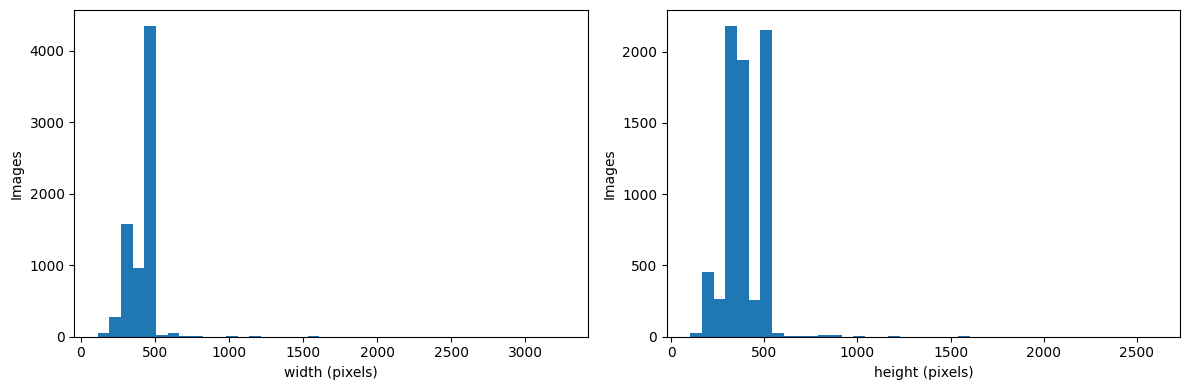

,width,height
"(0.0, 224.0]",153,200
"(224.0, 256.0]",140,377
"(256.0, 512.0]",6934,6692
"(512.0, 1024.0]",102,65
"(1024.0, inf]",20,15


,images
orientation,
landscape,4775
portrait,2263
near_square,311


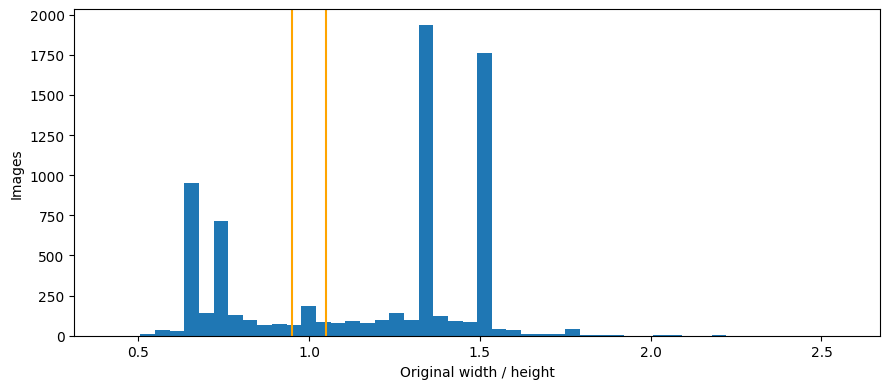

,id,width,height,aspect_ratio
5142,german_shorthaired_82,210,500,0.420000
1874,Abyssinian_175,600,234,2.564103


In [5]:
stats=valid[['width','height','aspect_ratio']].describe(percentiles=[.01,.05,.25,.5,.75,.95,.99]); display(stats); stats.to_csv(RESULT/'dimension_statistics.csv')
fig,axes=plt.subplots(1,2,figsize=(12,4))
for col,ax in zip(['width','height'],axes): ax.hist(valid[col],bins=40); ax.set_xlabel(f'{col} (pixels)'); ax.set_ylabel('Images')
save('image_dimensions.png')
bins=pd.DataFrame({col:pd.cut(valid[col],[0,224,256,512,1024,float('inf')]).value_counts(sort=False) for col in ['width','height']}); display(bins)
valid['orientation']=np.select([valid.aspect_ratio.lt(.95),valid.aspect_ratio.gt(1.05)],['portrait','landscape'],default='near_square')
display(valid.orientation.value_counts().to_frame('images'))
plt.figure(figsize=(9,4)); plt.hist(valid.aspect_ratio,bins=50); plt.axvline(.95,color='orange'); plt.axvline(1.05,color='orange'); plt.xlabel('Original width / height'); plt.ylabel('Images'); save('aspect_ratio_distribution.png')
display(valid.loc[[valid.aspect_ratio.idxmin(),valid.aspect_ratio.idxmax()],['id','width','height','aspect_ratio']])

## 5. Lưới ảnh 37 lớp
Chọn một ảnh hợp lệ mỗi class ID, seed 42, ưu tiên official trainval. EXIF transpose và RGB chỉ áp dụng trên bản sao để hiển thị, không ghi ảnh nguồn. RGBA được ghép lên nền trắng khi hiển thị để tránh màu nền trong suốt.

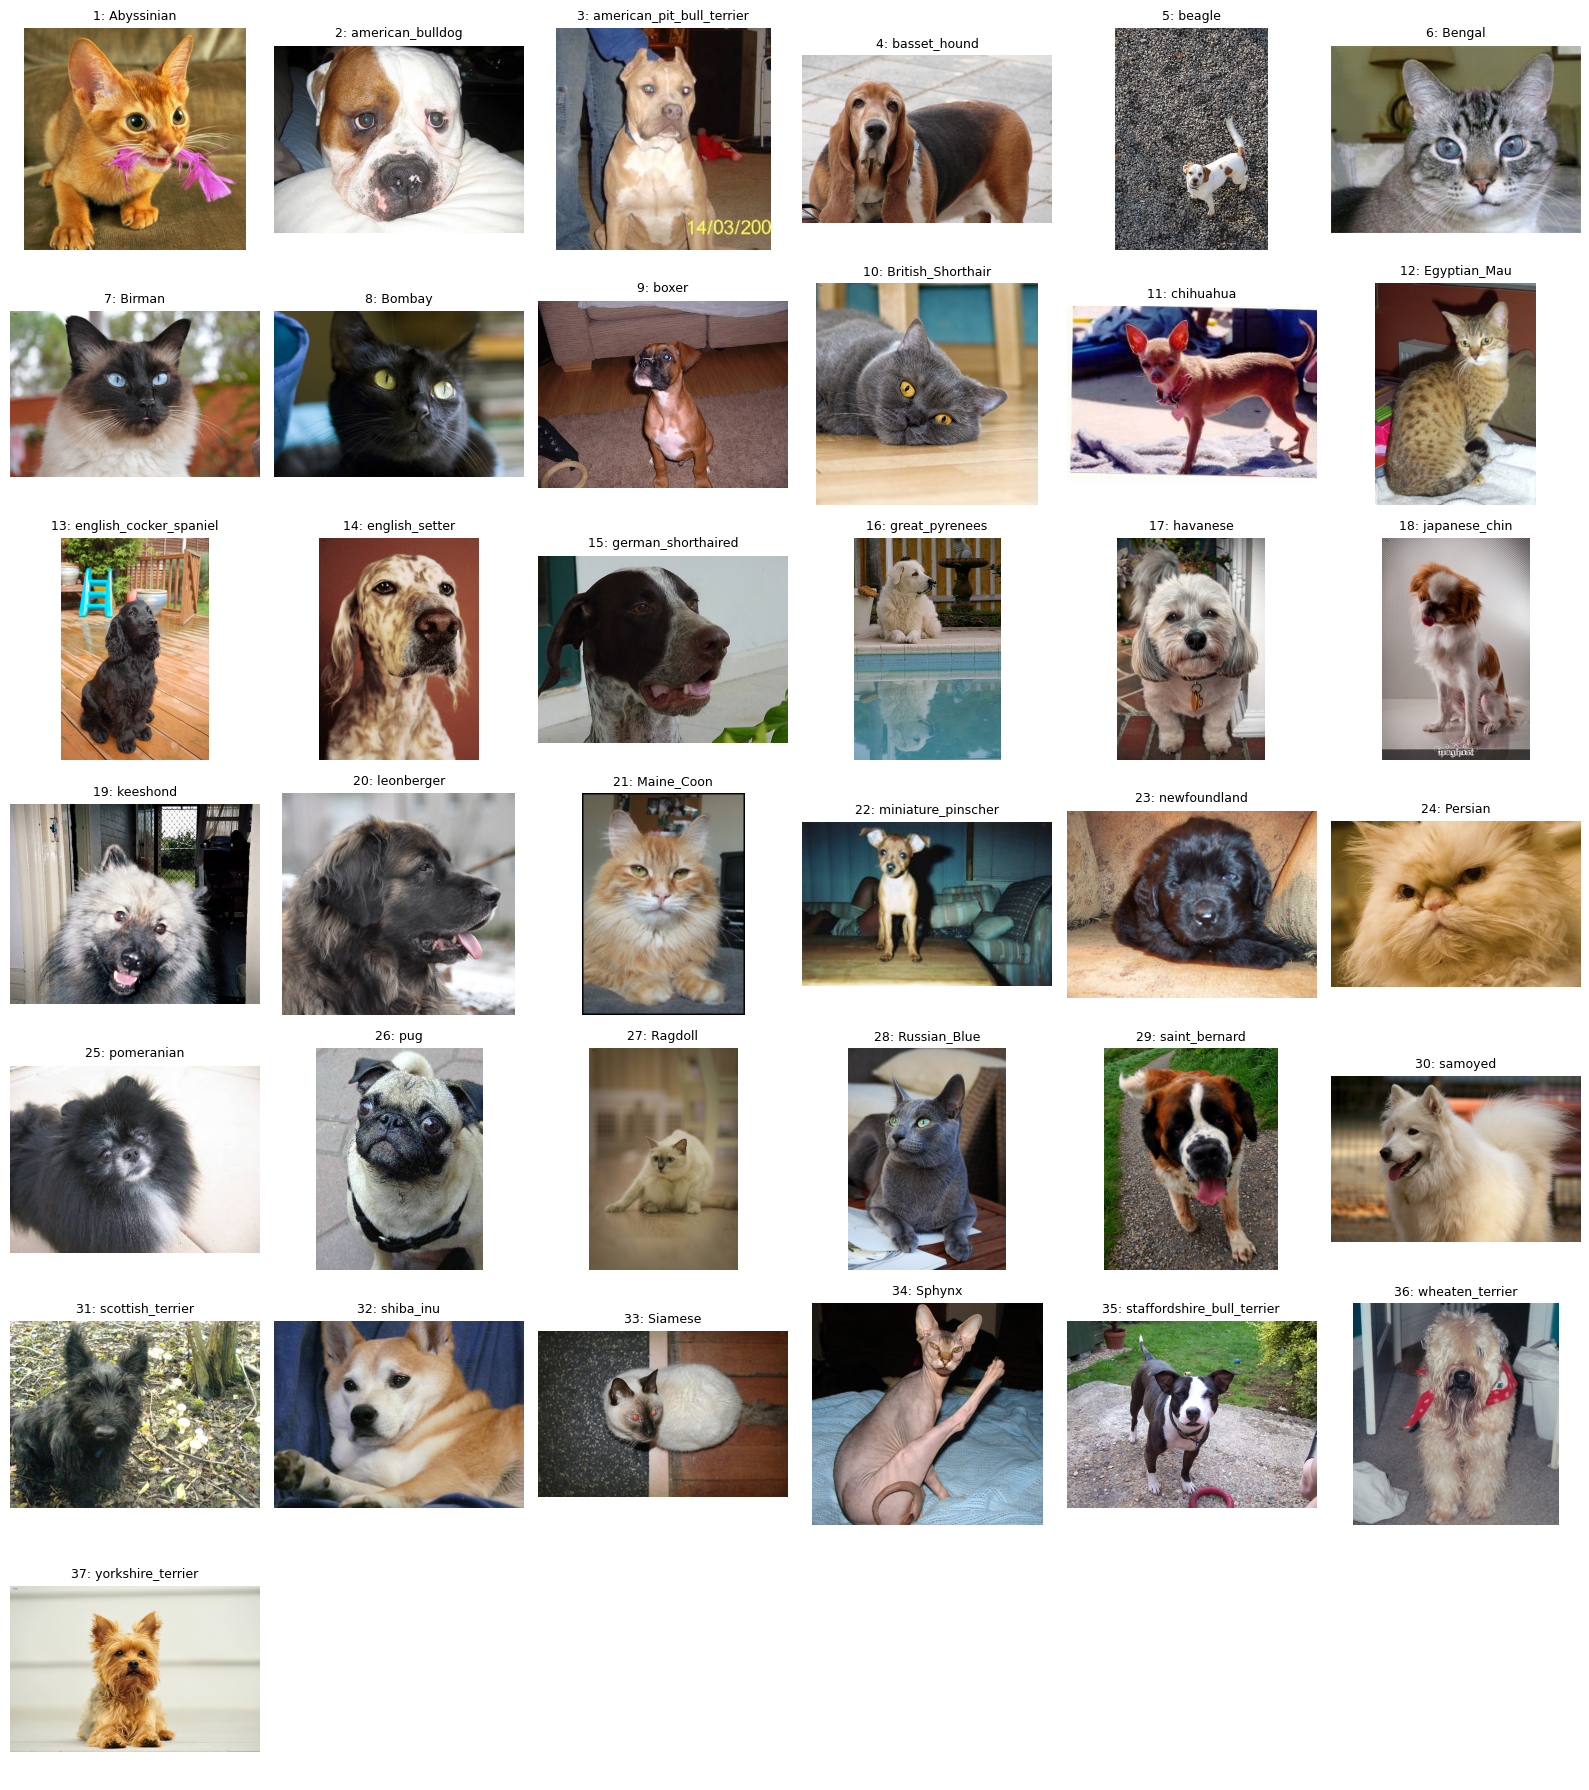

In [6]:
samples=valid[valid.split.eq('trainval')].sort_values('id').groupby('class_id',group_keys=False).sample(n=1,random_state=SEED).sort_values('class_id')
assert samples.class_id.nunique()==37
fig,axes=plt.subplots(7,6,figsize=(16,18))
for ax in axes.flat: ax.axis('off')
for ax,row in zip(axes.flat,samples.itertuples()):
    with Image.open(DATA/'images'/f'{row.id}.jpg') as im:
        im=ImageOps.exif_transpose(im)
        if im.mode=='RGBA':
            bg=Image.new('RGBA',im.size,'white'); im=Image.alpha_composite(bg,im)
        ax.imshow(im.convert('RGB'))
    ax.set_title(f'{row.class_id}: {row.class_name}',fontsize=9)
save('sample_grid_37_classes.png')
samples[['class_id','class_name','id','split']].to_csv(RESULT/'sample_ids.csv',index=False)

## 6. Đối chiếu audit cũ và kết luận preprocessing
Audit tham chiếu dùng train/val/test 2944/736/3669; EDA này dùng official trainval/test, không mang split cá nhân sang nhiệm vụ nhóm. So sánh tổng theo lớp và mode, không ép sửa dữ liệu để khớp.

In [7]:
ref=RESULT/'reference'
previous=pd.read_csv(ref/'class_counts.csv')
old_counts=previous.set_index('class_id')[['train','val','test']].sum(axis=1)
new_counts=counts.reset_index().set_index('class_id').total
comparison=pd.DataFrame({'old':old_counts,'current':pd.Series({int(i)-1:int(v) for i,v in new_counts.items()})})
comparison['delta']=comparison.current-comparison.old; display(comparison)
old_audit=json.loads((ref/'audit.json').read_text())
mode_match=old_audit['image_modes']==valid['mode'].value_counts().to_dict()
summary={'annotated_images':len(a),'classes':int(a.class_id.nunique()),'splits':a['split'].value_counts().to_dict(),'species':species.to_dict(),'modes':mode_counts.to_dict(),'statuses':status_counts.to_dict(),'measured_images':len(valid),'grid_classes':int(samples.class_id.nunique()),'old_class_counts_match':bool(comparison.delta.eq(0).all()),'old_modes_match':mode_match,'orientation':valid.orientation.value_counts().to_dict(),'annotation_sha256':{name:hashlib.sha256((DATA/'annotations'/f'{name}.txt').read_bytes()).hexdigest() for name in ['list','trainval','test']}}
(RESULT/'summary.json').write_text(json.dumps(summary,indent=2))
print(json.dumps(summary,indent=2))
display(Markdown(f"""### Nhận xét dựa trên số liệu
- {len(a)} mẫu, 37 giống; số ảnh mỗi giống từ {counts.total.min()} đến {counts.total.max()}, tỉ lệ max/min {counts.total.max()/counts.total.min():.3f}. Cần phân biệt mức cân bằng lớp với tỉ lệ loài: Cat {species.get('Cat',0)/len(a):.1%}, Dog {species.get('Dog',0)/len(a):.1%}.
- Width từ {valid.width.min():.0f} đến {valid.width.max():.0f}; height từ {valid.height.min():.0f} đến {valid.height.max():.0f}; aspect ratio {valid.aspect_ratio.min():.3f}–{valid.aspect_ratio.max():.3f}. Resize ép vuông có thể bóp méo hình; resize giữ tỉ lệ rồi crop 224 có thể cắt mất bộ phận ở ảnh cực ngang/dọc. Cần kiểm tra crop trực quan khi xây transform train.
- ViT-B/16 ở cấu hình 224×224 cần kích thước đồng nhất (14×14 patch), RGB 3 kênh và normalization khớp weights ImageNet; EDA không ước lượng mean/std trên test.
- Có {(valid['mode']!='RGB').sum()} ảnh non-RGB đọc được; không loại như ảnh hỏng. Với RGBA cần quyết định ghép nền rõ ràng trước RGB; grayscale lặp kênh và CMYK chuyển RGB khi có. EXIF transpose nên áp dụng trước resize.
- Thiếu {status_counts['missing']}, lỗi giải mã {status_counts['decode_error']}, kích thước lỗi {status_counts['invalid_size']}. Nếu xuất hiện khi chạy lại, điều tra ID trong anomalies.csv trước khi train; không âm thầm bỏ nhãn.
- Metadata, .mat, ảnh ngoài official annotation và trimap được liệt kê riêng trong inventory.json, không nhập vào tổng mẫu phân loại. Không kiểm tra near-duplicate hay sửa nhãn bằng mắt trong phạm vi T11.
"""))
assert len(valid)+int((images.status!='ok').sum())==len(a)
assert summary['grid_classes']==37
assert len(list(FIG.glob('*.png')))==6
print('T11 notebook execution complete')

,old,current,delta
0,198,198,0
1,200,200,0
2,200,200,0
3,200,200,0
4,200,200,0
5,200,200,0
6,200,200,0
7,184,184,0
8,199,199,0
9,200,200,0


{
  "annotated_images": 7349,
  "classes": 37,
  "splits": {
    "trainval": 3680,
    "test": 3669
  },
  "species": {
    "Cat": 2371,
    "Dog": 4978
  },
  "modes": {
    "RGB": 7346,
    "L": 0,
    "RGBA": 3,
    "CMYK": 0
  },
  "statuses": {
    "ok": 7349,
    "missing": 0,
    "decode_error": 0,
    "invalid_size": 0
  },
  "measured_images": 7349,
  "grid_classes": 37,
  "old_class_counts_match": true,
  "old_modes_match": true,
  "orientation": {
    "landscape": 4775,
    "portrait": 2263,
    "near_square": 311
  },
  "annotation_sha256": {
    "list": "6a54ab256e22f7a33c6f17a7669e58ea5f6f9c7a080ec2622c205aefd4b354da",
    "trainval": "408f3f609481b939c94634169e6413414b733a3faeba440cbdcc5c02142eebdc",
    "test": "a5454003774ffe01f4f322756d3ba5495bae21cb30bb217ab285dbfa2bef245c"
  }
}


### Nhận xét dựa trên số liệu
- 7349 mẫu, 37 giống; số ảnh mỗi giống từ 184 đến 200, tỉ lệ max/min 1.087. Cần phân biệt mức cân bằng lớp với tỉ lệ loài: Cat 32.3%, Dog 67.7%.
- Width từ 114 đến 3264; height từ 103 đến 2606; aspect ratio 0.420–2.564. Resize ép vuông có thể bóp méo hình; resize giữ tỉ lệ rồi crop 224 có thể cắt mất bộ phận ở ảnh cực ngang/dọc. Cần kiểm tra crop trực quan khi xây transform train.
- ViT-B/16 ở cấu hình 224×224 cần kích thước đồng nhất (14×14 patch), RGB 3 kênh và normalization khớp weights ImageNet; EDA không ước lượng mean/std trên test.
- Có 3 ảnh non-RGB đọc được; không loại như ảnh hỏng. Với RGBA cần quyết định ghép nền rõ ràng trước RGB; grayscale lặp kênh và CMYK chuyển RGB khi có. EXIF transpose nên áp dụng trước resize.
- Thiếu 0, lỗi giải mã 0, kích thước lỗi 0. Nếu xuất hiện khi chạy lại, điều tra ID trong anomalies.csv trước khi train; không âm thầm bỏ nhãn.
- Metadata, .mat, ảnh ngoài official annotation và trimap được liệt kê riêng trong inventory.json, không nhập vào tổng mẫu phân loại. Không kiểm tra near-duplicate hay sửa nhãn bằng mắt trong phạm vi T11.


T11 notebook execution complete
